In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [12]:
file_path = "ObesityDataSet_raw_and_data_sinthetic.csv"
df = pd.read_csv(file_path)

# 1. Display basic info


In [ ]:
# 1. Display basic info
print('\n--- Dataset Info ---')
print(df.info())
len(df)


--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF         

2111

# 2. Data Cleaning


In [24]:
# 2. Data Cleaning
print('\n--- Cleaning Data ---')
print(f'Initial row count: {len(df)}')
df_example = df.drop_duplicates()
print(f'Row count after cleaning: {len(df_example)}')
#the result show that there are duplicates in the dataset, so we will remove them.
df = df.drop_duplicates()
len(df)



--- Cleaning Data ---
Initial row count: 2087
Row count after cleaning: 2087


2087

# 3. Categorical Encodings


In [26]:
# 3. Categorical Encodings
print('\n--- Encoding Categorical Variables ---')

# Binary categorical mapping
binary_cols = [
    'Gender',
    'family_history_with_overweight',
    'FAVC',
    'SMOKE',
    'SCC',
]
for col in binary_cols:
  if col in df.columns:
    # Assuming standard binary values like yes/no or Male/Female
    unique_vals = df[col].unique()
    df[col] = df[col].map({unique_vals[0]: 0, unique_vals[1]: 1})

# Ordinal mapping for frequency columns
ordinal_mapping = {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3}
for col in ['CAEC', 'CALC']:
  if col in df.columns:
    df[col] = df[col].map(ordinal_mapping)

# One-Hot Encoding for nominal features (e.g., MTRANS)
df = pd.get_dummies(df, columns=['MTRANS'], drop_first=True)



# Label Encoding for the target variable (NObeyesdad)
target_col = 'NObeyesdad'
le = LabelEncoder()
if target_col in df.columns:
  df[target_col] = le.fit_transform(df[target_col])
  print('Target classes encoded:', dict(zip(le.classes_, range(len(le.classes_)))))


--- Encoding Categorical Variables ---
Target classes encoded: {'Insufficient_Weight': 0, 'Normal_Weight': 1, 'Obesity_Type_I': 2, 'Obesity_Type_II': 3, 'Obesity_Type_III': 4, 'Overweight_Level_I': 5, 'Overweight_Level_II': 6}


# 4. Feature Scaling 


In [ ]:
# 4. Feature Scaling 
print('\n--- Scaling Numerical Features ---')
numerical_cols = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
scaler = StandardScaler()
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])


--- Scaling Numerical Features ---


# 5. Exploratory Data Analysis & Visualizations



--- Generating Visualizations ---


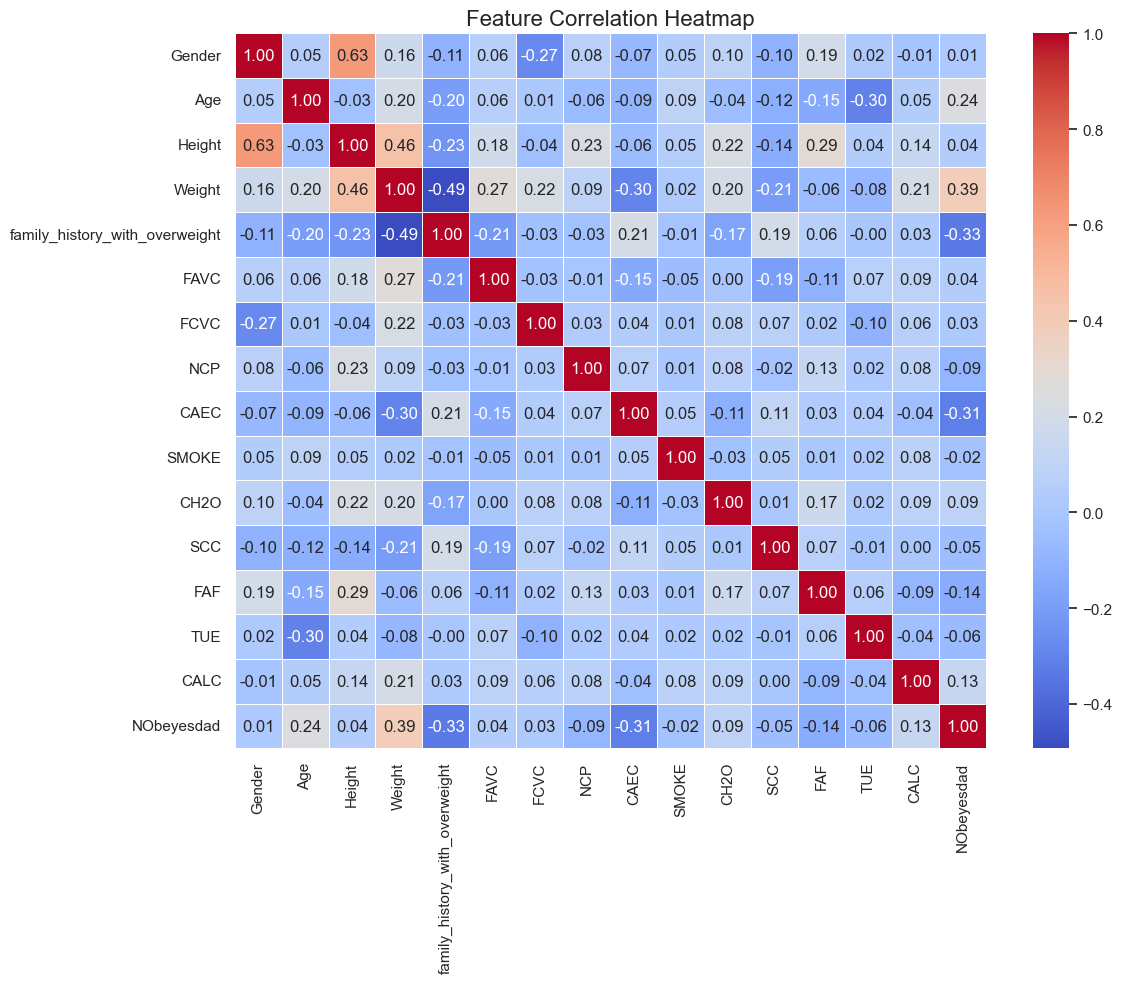

In [29]:
# 5. Exploratory Data Analysis & Visualizations
print('\n--- Generating Visualizations ---')
sns.set_theme(style='whitegrid')

# Figure 1: Correlation Heatmap
plt.figure(figsize=(12, 10))
numeric_df = df.select_dtypes(include=[np.number])
correlation_matrix = numeric_df.corr()
sns.heatmap(
    correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5
)
plt.title('Feature Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

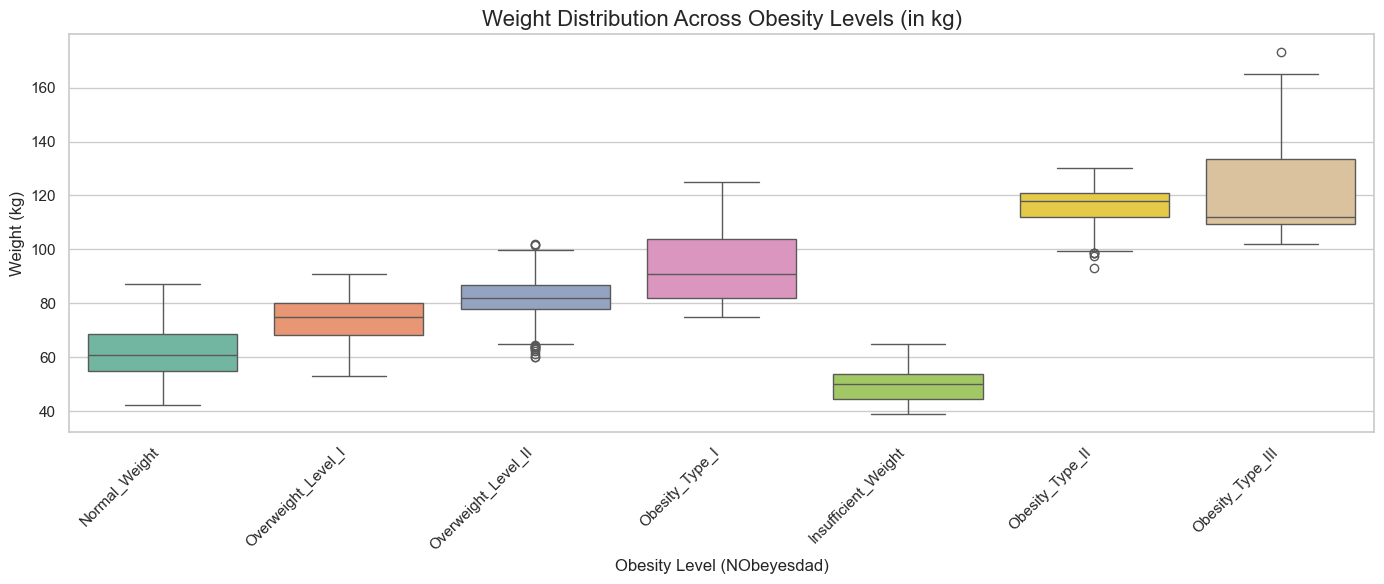

In [35]:
# Figure 2: Weight vs Target Distribution (Boxplot using raw data)
plt.figure(figsize=(14, 6))

df_raw = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')

sns.boxplot(
    x='NObeyesdad', y='Weight', data=df_raw, palette='Set2', hue='NObeyesdad', legend=False
)

plt.xticks(rotation=45, ha='right')
plt.title('Weight Distribution Across Obesity Levels (in kg)', fontsize=16)
plt.xlabel('Obesity Level (NObeyesdad)', fontsize=12)
plt.ylabel('Weight (kg)', fontsize=12)
plt.tight_layout()
plt.show()

C:\Users\souma\AppData\Local\Temp\ipykernel_31776\794726925.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='NObeyesdad', data=df_raw, palette='Set1', order=['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III'])


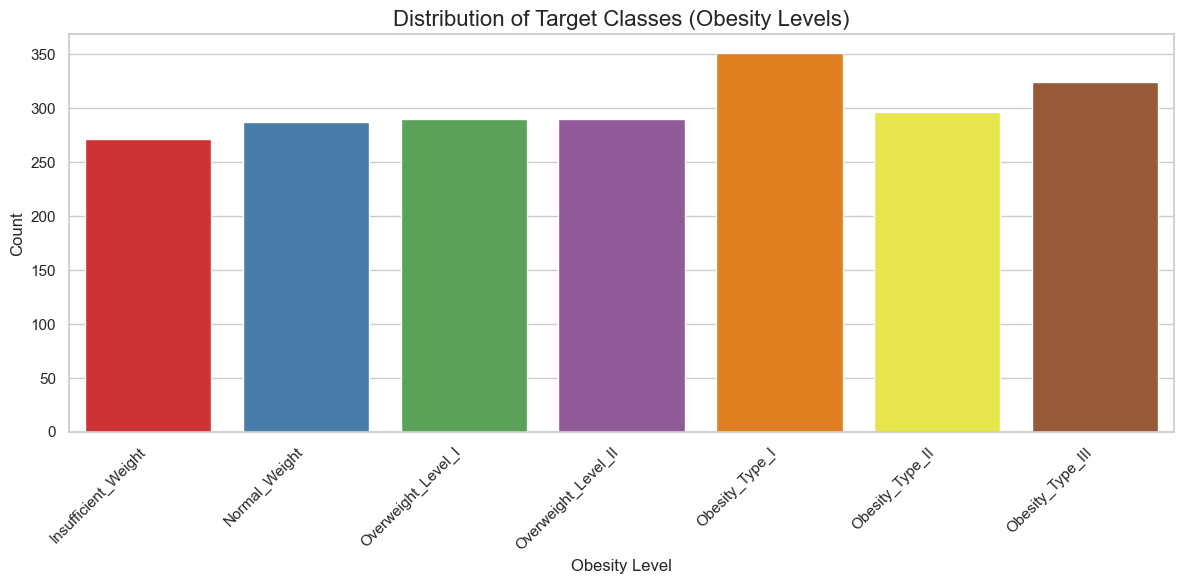

In [ ]:
#Figure 3: Distribution of Target Classes (Countplot using raw data)
plt.figure(figsize=(12, 6))
sns.countplot(x='NObeyesdad', data=df_raw, palette='Set1', order=['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III'])
plt.xticks(rotation=45, ha='right')
plt.title('Distribution of Target Classes (Obesity Levels)', fontsize=16)
plt.xlabel('Obesity Level', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.tight_layout()

plt.show()